# 05 优化器、学习率调整与正则化


本篇对应 **day05**，是「06-深度学习神经网络」7篇笔记中的第5篇。承接04的网络训练和损失函数，继续学习指数移动平均、Momentum、AdaGrad、RMSprop、Adam、学习率衰减、Dropout、BatchNorm，以及手机价格分类的数据准备。

资料：[深度学习神经网络课程资料](https://pan.baidu.com/s/1FPhKS2qMBgnqVOXCyhBTog?pwd=1234)，提取码 `1234`。已核对 `04_深度学习神经网络/视频/day05` 的 **20个视频文件标题**，其中包含两段PyCharm扩展内容。原教师 `课堂笔记.zip`、`课件.zip` 和项目数据正文未取得，视频未逐段转录；本文按已核对目录组织，说明、示例和图均独立编写，不作为教师原文或课堂代码的复刻。

全部为Markdown单元，Python代码按顺序复制到代码单元即可运行。所有图均内嵌在当前Notebook中，不依赖单独图片文件。


## 本篇学习路线

| 对应视频 | 内容 | 重点 |
| --- | --- | --- |
| 01—05、08—09 | 梯度回顾、指数平均、四种优化方法 | 分清梯度、状态、有效步长 |
| 06—07 | PyCharm插件与主题 | 作为开发工具补充，不改变训练原理 |
| 10—14 | 学习率背景与三种衰减 | 记录本轮使用的lr，正确调用scheduler |
| 15—16 | Dropout | 训练随机失活，评价关闭 |
| 17—18 | BatchNorm | 区分batch统计量、运行统计量和可训练参数 |
| 19—20 | 手机价格分类需求和数据准备 | 明确标签、划分数据、只在训练集拟合预处理 |

手机分类本篇只准备数据和batch；完整ANN模型训练留给06。关于原课程字段和具体数据规模，不用未读取的文件内容作结论。


## 1. 环境与约定

优化器和正则化使用 `torch`；手机表格练习使用 `numpy、pandas、scikit-learn`。所有例子CPU即可运行，练习数据在内存生成，不下载原课程数据。

```bash
python -m pip install torch numpy pandas scikit-learn
```

```python
from pathlib import Path
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(2026)
print("PyTorch:", torch.__version__)
```

代码按顺序执行。涉及优化器公式时，先采用无权重衰减、无特殊变体的基本设置，避免把其他选项混进推导。


## 2. 梯度回顾：backward与step各做什么

`loss.backward()` 计算并累积梯度，`optimizer.step()` 根据当前梯度和优化器状态更新参数。梯度会累积，普通循环每次更新前必须清理。

```python
review_w = nn.Parameter(torch.tensor(1.0))
review_optimizer = torch.optim.SGD([review_w], lr=0.1)
review_optimizer.zero_grad(set_to_none=True)
review_loss = 0.5 * review_w.square()
review_loss.backward()
assert review_w.item() == 1.0
assert review_w.grad.item() == 1.0
review_optimizer.step()
assert abs(review_w.item() - 0.9) < 1e-6
```

损失值不是梯度值；梯度下降也不要求每个参数都减小。参数沿负梯度方向更新，当梯度为负时，参数可能增加。

优化器不会自己寻找模型：初始化时需要传入正确的 `model.parameters()`。训练中反复新建优化器会丢失Momentum/Adam等积累的状态，改变更新行为。


## 3. 指数移动平均：近期信息权重更高

对序列x，初始 `v0=0`：

$$v_t=\beta v_{t-1}+(1-\beta)x_t,\qquad 0\le\beta<1.$$

β越大，平均越平滑、对新变化响应越慢。过去第k步的权重按β的幂衰减，不能理解成“只平均最近固定几项”。`1/(1-β)` 可作为粗略时间尺度，不是严格窗口大小。

```python
ema_values = [10.0, 20.0, 30.0]
ema_beta = 0.9
ema_state = 0.0
ema_raw, ema_corrected = [], []
for step, value in enumerate(ema_values, start=1):
    ema_state = ema_beta * ema_state + (1 - ema_beta) * value
    ema_raw.append(ema_state)
    ema_corrected.append(ema_state / (1 - ema_beta ** step))
assert np.allclose(ema_raw, [1.0, 2.9, 5.61])
assert abs(ema_corrected[0] - 10.0) < 1e-10
print(ema_raw)
print(ema_corrected)
```

从0起步会让初期平均偏向0，除以 `1-β^t` 是零初始化偏差修正。它不把序列恢复成“真实值”，只是修正这种特定的初始缩放偏差。

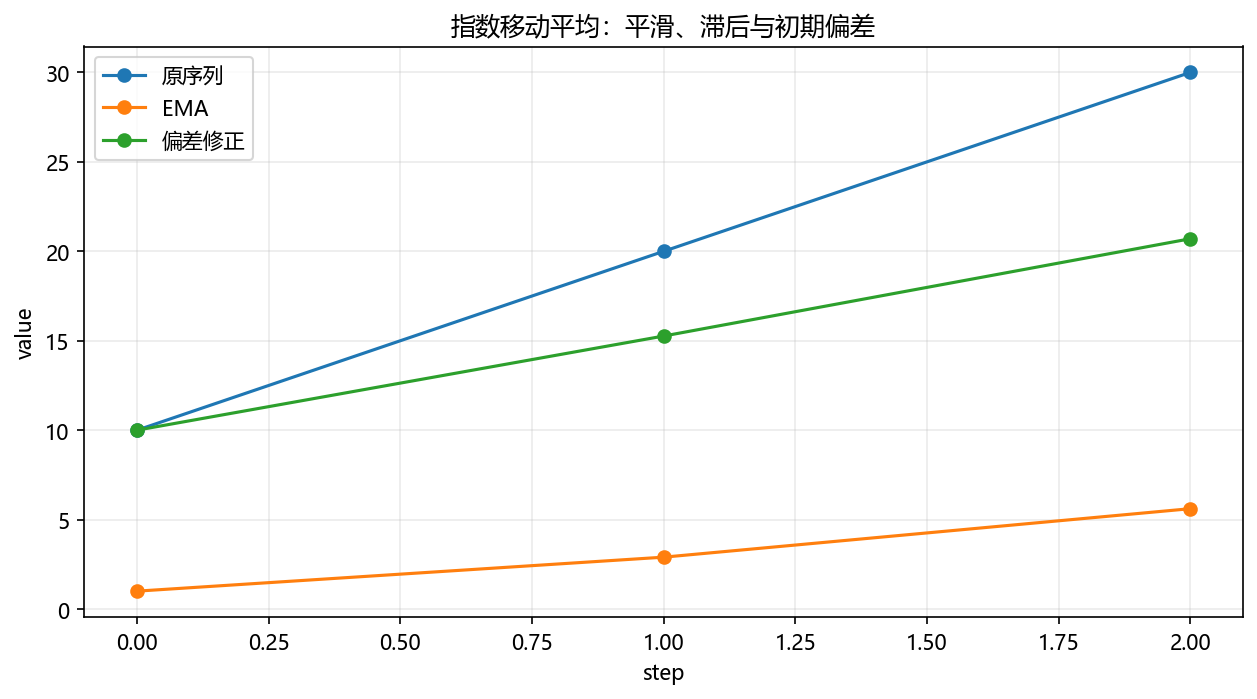

优化器把这些平滑思想用于梯度或梯度平方，并不是直接对loss取平均后就能得到更好的参数。


## 4. Momentum：沿历史方向积累更新

以PyTorch SGD常见设置 `dampening=0、nesterov=False、weight_decay=0` 为例：

$$b_t=\mu b_{t-1}+g_t,\qquad
\theta_t=\theta_{t-1}-\eta b_t.$$

g是当前梯度，μ是动量系数。首步缓冲区初始化为当前梯度。持续同方向的梯度会积累，来回变化的部分会被平滑。

一些教材使用 `v=βv+(1-β)g` 的归一化EMA形式；它与上式的尺度不同，不能不调整学习率就说数值完全一致。PyTorch基本SGD动量不自动给当前梯度乘 `1-μ`。

```python
momentum_w = nn.Parameter(torch.tensor(1.0, dtype=torch.float64))
momentum_optimizer = torch.optim.SGD([momentum_w], lr=0.1, momentum=0.9)
momentum_trace = []
for step in range(2):
    momentum_optimizer.zero_grad(set_to_none=True)
    (0.5 * momentum_w.square()).backward()
    momentum_optimizer.step()
    buffer = momentum_optimizer.state[momentum_w]["momentum_buffer"].item()
    momentum_trace.append((momentum_w.item(), buffer))
assert np.allclose(momentum_trace, [(0.9, 1.0), (0.72, 1.8)])
print(momentum_trace)
```

第二次梯度为0.9，buffer为 `0.9×1+0.9=1.8`，参数更新到0.72。Momentum可能加快稳定方向的进展，也可能因学习率或动量过大而过冲；它不保证每一步loss下降。


## 5. AdaGrad：累计梯度平方，按坐标调整步长

基本形式，初始平方和为0：

$$s_t=s_{t-1}+g_t^2,\qquad
\theta_t=\theta_{t-1}-\eta\frac{g_t}{\sqrt{s_t}+\epsilon}.$$

乘方和除法逐元素执行。经常出现大梯度的坐标累计值大，更新会被缩小；累计平方和不会减小，因此后期有效步长可能越来越小。

```python
adagrad_w = nn.Parameter(torch.tensor(1.0, dtype=torch.float64))
adagrad_optimizer = torch.optim.Adagrad(
    [adagrad_w], lr=0.1, lr_decay=0.0,
    initial_accumulator_value=0.0, eps=1e-10,
)
adagrad_trace = []
for step in range(2):
    adagrad_optimizer.zero_grad(set_to_none=True)
    (0.5 * adagrad_w.square()).backward()
    adagrad_optimizer.step()
    accumulated = adagrad_optimizer.state[adagrad_w]["sum"].item()
    adagrad_trace.append((adagrad_w.item(), accumulated))
assert abs(adagrad_trace[0][0] - 0.9) < 1e-8
assert abs(adagrad_trace[1][1] - 1.81) < 1e-8
expected_adagrad_second = 0.9 - 0.1 * 0.9 / (1.81 ** 0.5 + 1e-10)
assert abs(adagrad_trace[1][0] - expected_adagrad_second) < 1e-8
print(adagrad_trace)
```

AdaGrad在稀疏特征等情形中有用途，但不代表总适合深层网络。不要把全局学习率η与每个坐标的有效缩放混为一谈。


## 6. RMSprop：让梯度平方的旧信息逐渐衰减

基本设置 `momentum=0、centered=False`：

$$s_t=\alpha s_{t-1}+(1-\alpha)g_t^2,\qquad
\theta_t=\theta_{t-1}-\eta\frac{g_t}{\sqrt{s_t}+\epsilon}.$$

相比AdaGrad永久累加，RMSprop用EMA追踪近期梯度平方。PyTorch这一基本接口不对s做Adam式零初始化偏差修正；ε的位置是平方根外。

```python
rmsprop_w = nn.Parameter(torch.tensor(1.0, dtype=torch.float64))
rmsprop_optimizer = torch.optim.RMSprop(
    [rmsprop_w], lr=0.1, alpha=0.9, eps=1e-8,
    momentum=0.0, centered=False,
)
rmsprop_optimizer.zero_grad(set_to_none=True)
(0.5 * rmsprop_w.square()).backward()
rmsprop_optimizer.step()
rmsprop_square_average = rmsprop_optimizer.state[rmsprop_w]["square_avg"].item()
assert abs(rmsprop_square_average - 0.1) < 1e-12
expected_rmsprop_w = 1.0 - 0.1 / (0.1 ** 0.5 + 1e-8)
assert abs(rmsprop_w.item() - expected_rmsprop_w) < 1e-10
print(rmsprop_w.item(), rmsprop_square_average)
```

首步与SGD或Adam不一定同样大小。因此换优化器时，仅保持同一个lr数字不代表保持同样的更新步长。


## 7. Adam：梯度的一阶与二阶信息

基本Adam同时使用梯度EMA和梯度平方EMA：

$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\quad
v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2.$$

零初始化偏差修正：

$$\hat m_t=\frac{m_t}{1-\beta_1^t},\quad
\hat v_t=\frac{v_t}{1-\beta_2^t},\quad
\theta_t=\theta_{t-1}-\eta\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}.$$

```python
adam_w = nn.Parameter(torch.tensor(1.0, dtype=torch.float64))
adam_optimizer = torch.optim.Adam(
    [adam_w], lr=0.1, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0,
)
adam_optimizer.zero_grad(set_to_none=True)
(0.5 * adam_w.square()).backward()
adam_optimizer.step()
adam_state = adam_optimizer.state[adam_w]
assert abs(adam_state["exp_avg"].item() - 0.1) < 1e-12
assert abs(adam_state["exp_avg_sq"].item() - 0.001) < 1e-12
assert abs(adam_w.item() - (1.0 - 0.1 / (1.0 + 1e-8))) < 1e-10
print(adam_w.item())
```

Adam常用作起点，但不是无需调学习率、无需数据预处理的万能选择。β1和β2控制不同状态，不是“两个学习率”。本节不加入weight_decay、AMSGrad等选项；AdamW的解耦权重衰减又是额外设计，不能不加说明地与Adam的普通权重衰减画等号。


## 8. 优化器比较：先看机制，再做同任务验证

| 方法 | 保存的信息 | 主要作用 | 容易忽略 |
| --- | --- | --- | --- |
| SGD | 基本设置下无历史平均 | 按当前梯度更新 | 学习率很关键 |
| Momentum | 历史梯度方向buffer | 平滑并积累方向 | 可能过冲；实现尺度要对齐 |
| AdaGrad | 历史梯度平方累计 | 按坐标缩放 | 累计导致有效步长持续缩小 |
| RMSprop | 近期梯度平方EMA | 缓解永久累计 | alpha与eps也影响步长 |
| Adam | 梯度EMA与平方EMA | 平滑方向并按坐标缩放 | 状态和偏差修正不可漏 |

下面用同一起点和同一个二次函数观察轨迹：

$$L(u,v)=\frac12(10u^2+v^2).$$

```python
optimizer_specs = {
    "SGD": (torch.optim.SGD, {"lr": 0.08}),
    "Momentum": (torch.optim.SGD, {"lr": 0.08, "momentum": 0.9}),
    "AdaGrad": (torch.optim.Adagrad, {"lr": 0.3}),
    "RMSprop": (torch.optim.RMSprop, {"lr": 0.05, "alpha": 0.9}),
    "Adam": (torch.optim.Adam, {"lr": 0.1}),
}
optimizer_paths = {}
for name, (factory, settings) in optimizer_specs.items():
    position = nn.Parameter(torch.tensor([2.0, 2.0], dtype=torch.float64))
    optimizer = factory([position], **settings)
    coordinates = [position.detach().clone()]
    for step in range(40):
        optimizer.zero_grad(set_to_none=True)
        objective = 0.5 * (10 * position[0].square() + position[1].square())
        objective.backward()
        optimizer.step()
        coordinates.append(position.detach().clone())
    optimizer_paths[name] = torch.stack(coordinates)
    assert optimizer_paths[name].shape == (41, 2)
    assert torch.isfinite(optimizer_paths[name]).all()
```

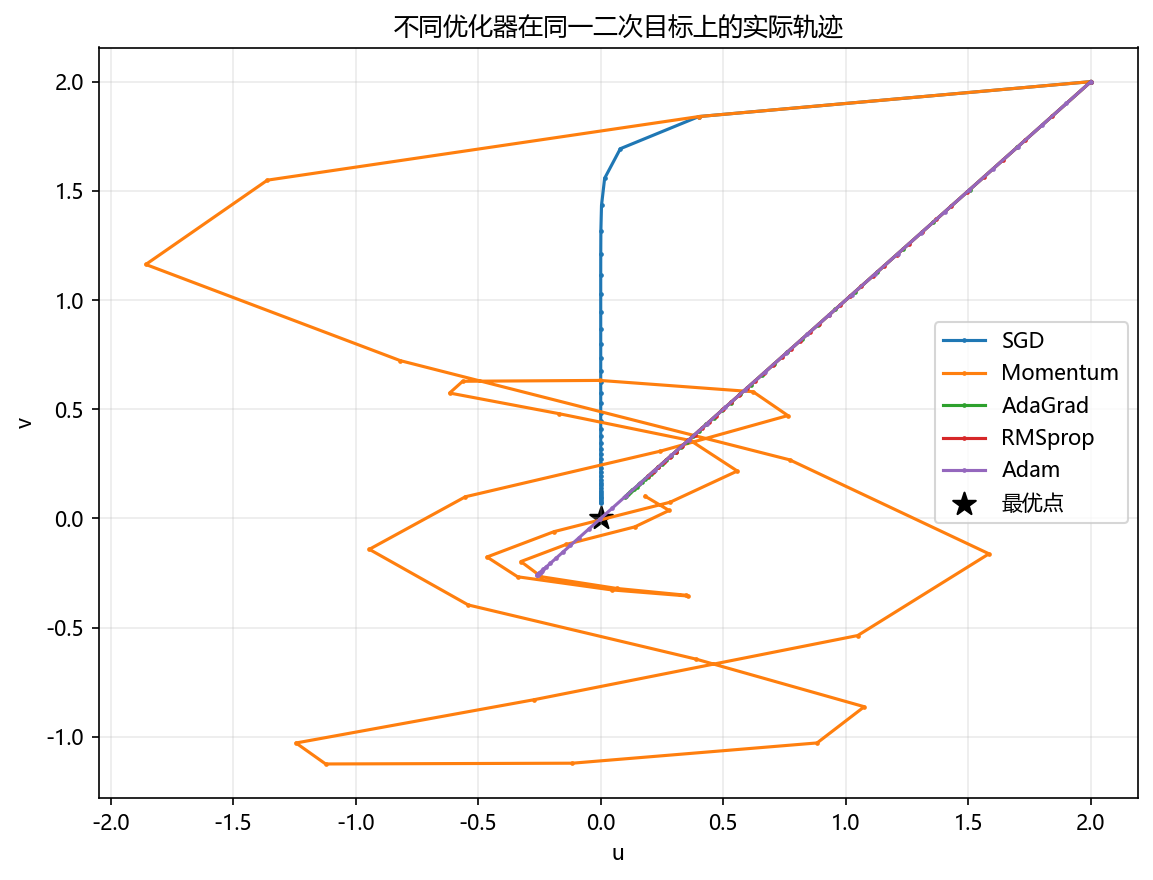

这些学习率为本例分别指定，没有做充分调参；图用于解释运动方式，**不能据此宣布某个优化器普遍更好**。真实比较要控制数据划分、模型、训练预算和评价指标，并在验证集选择超参数。


## 9. 学习率调整：变化的是全局更新尺度

较大的学习率可能让初期进展快，也可能不稳定；较小的学习率有利于细化，但过早衰减会导致学习停滞。scheduler按策略修改优化器中的lr，优化器仍负责参数更新。

一般epoch级策略的顺序：

`本轮batch训练 → optimizer.step() → epoch结束 → scheduler.step()`。

每个epoch包含多次optimizer更新，但scheduler只在epoch末调用一次。若改成每batch调用，衰减速度随调用次数改变。日志应记录本轮**真正使用**的lr，不能只在scheduler更新后记录并声称是刚刚训练用的值。

本篇展示StepLR、MultiStepLR和ExponentialLR。课程文件标题为“指数间隔”，这里以PyTorch指数衰减接口做独立实现，不声称视频具体参数相同。


## 10. StepLR：每隔固定调用次数衰减

$$lr_k=lr_0\gamma^{\lfloor k/s\rfloor}.$$

k是已完成的epoch级scheduler更新数，s为step_size，γ为乘数。初始lr=0.1、step_size=3、gamma=0.5，每完成3轮训练后把下一轮lr减半。

```python
step_parameter = nn.Parameter(torch.tensor(1.0))
step_optimizer = torch.optim.SGD([step_parameter], lr=0.1)
step_scheduler = torch.optim.lr_scheduler.StepLR(
    step_optimizer, step_size=3, gamma=0.5)
step_lr_used = []
for epoch in range(9):
    step_lr_used.append(step_optimizer.param_groups[0]["lr"])
    step_optimizer.zero_grad(set_to_none=True)
    step_parameter.square().backward()
    step_optimizer.step()
    step_scheduler.step()
assert np.allclose(step_lr_used, [0.1]*3 + [0.05]*3 + [0.025]*3)
print(step_lr_used)
```

第3轮训练仍使用0.1，第3轮结束后变为0.05，第4轮才使用新值。按这种显式顺序理解，比只背“第3轮衰减”更清楚。


## 11. MultiStepLR：在指定节点衰减

MultiStepLR用于不等间隔的预定衰减节点，例如完成第2轮和第5轮训练后修改下一轮lr。

```python
milestone_parameter = nn.Parameter(torch.tensor(1.0))
milestone_optimizer = torch.optim.SGD([milestone_parameter], lr=0.1)
milestone_scheduler = torch.optim.lr_scheduler.MultiStepLR(
    milestone_optimizer, milestones=[2, 5], gamma=0.1)
milestone_lr_used = []
for epoch in range(7):
    milestone_lr_used.append(milestone_optimizer.param_groups[0]["lr"])
    milestone_optimizer.zero_grad(set_to_none=True)
    milestone_parameter.square().backward()
    milestone_optimizer.step()
    milestone_scheduler.step()
assert np.allclose(milestone_lr_used, [0.1, 0.1, 0.01, 0.01, 0.01, 0.001, 0.001])
print(milestone_lr_used)
```

milestones计数取决于调用scheduler的节奏。一个epoch结束后调用一次，就按epoch解释；每个batch都调用则按batch计，不能在代码与说明中混用单位。


## 12. ExponentialLR：每次按固定比例衰减

$$lr_k=lr_0\gamma^k.$$

γ=0.9表示每次变为原来的90%，不是直接减去0.9。

```python
exponential_parameter = nn.Parameter(torch.tensor(1.0))
exponential_optimizer = torch.optim.SGD([exponential_parameter], lr=0.1)
exponential_scheduler = torch.optim.lr_scheduler.ExponentialLR(
    exponential_optimizer, gamma=0.9)
exponential_lr_used = []
for epoch in range(8):
    exponential_lr_used.append(exponential_optimizer.param_groups[0]["lr"])
    exponential_optimizer.zero_grad(set_to_none=True)
    exponential_parameter.square().backward()
    exponential_optimizer.step()
    exponential_scheduler.step()
assert np.allclose(exponential_lr_used, [0.1 * 0.9**i for i in range(8)])
```

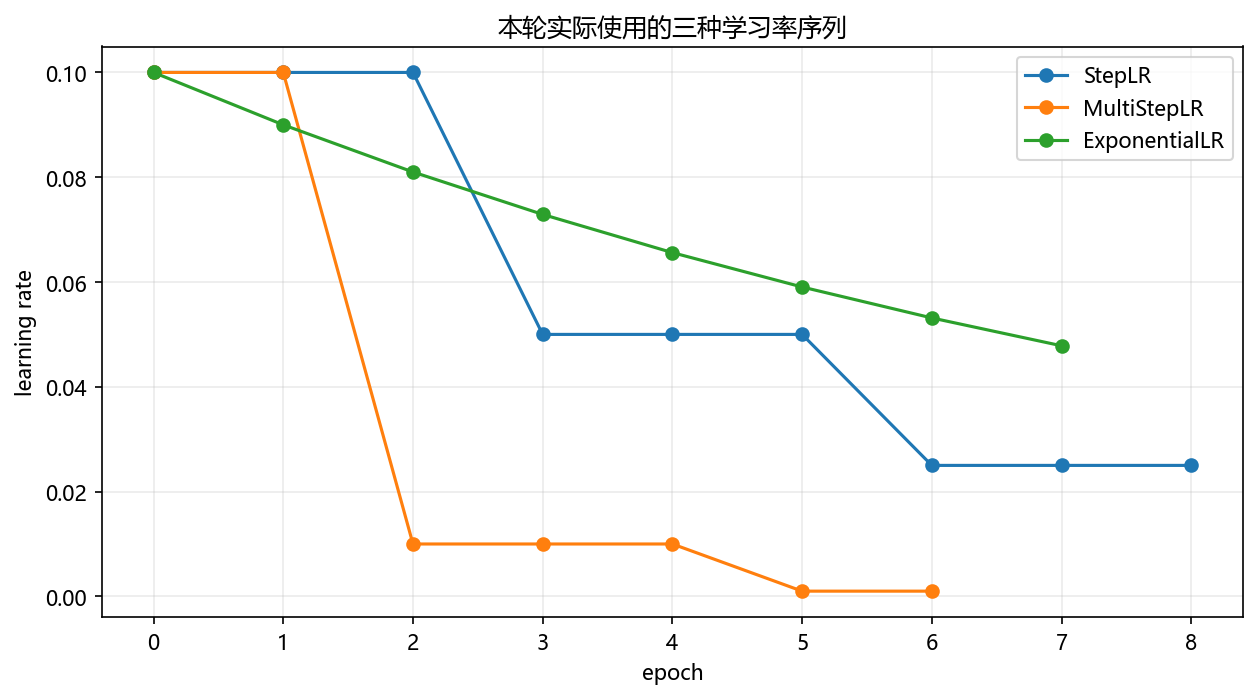

图中参数与衰减节点为本篇演示设置，横轴为开始计数的训练轮，显示该轮更新使用的lr。真实训练还可以按验证损失调整，如ReduceLROnPlateau需要传入验证指标；不要用最终测试集决定衰减时机。


## 13. 保存训练状态：优化器状态也属于训练进度

继续训练时，不只需要权重，还需要优化器历史状态、scheduler状态和训练轮数。推理只需要合适的模型结构与模型状态。

```python
checkpoint_model = nn.Linear(2, 1)
checkpoint_optimizer = torch.optim.Adam(checkpoint_model.parameters(), lr=0.01)
checkpoint_scheduler = torch.optim.lr_scheduler.StepLR(
    checkpoint_optimizer, step_size=2, gamma=0.5)
checkpoint_optimizer.zero_grad(set_to_none=True)
checkpoint_model(torch.ones(2, 2)).square().mean().backward()
checkpoint_optimizer.step()
checkpoint_scheduler.step()

# 内存中的深拷贝演示，不写额外模型文件
import copy
training_checkpoint = copy.deepcopy({
    "model": checkpoint_model.state_dict(),
    "optimizer": checkpoint_optimizer.state_dict(),
    "scheduler": checkpoint_scheduler.state_dict(),
    "epoch": 1,
})
restored_model = nn.Linear(2, 1)
restored_optimizer = torch.optim.Adam(restored_model.parameters(), lr=0.01)
restored_scheduler = torch.optim.lr_scheduler.StepLR(
    restored_optimizer, step_size=2, gamma=0.5)
restored_model.load_state_dict(training_checkpoint["model"])
restored_optimizer.load_state_dict(training_checkpoint["optimizer"])
restored_scheduler.load_state_dict(training_checkpoint["scheduler"])
assert len(restored_optimizer.state) == 2
assert restored_scheduler.last_epoch == checkpoint_scheduler.last_epoch
assert torch.equal(restored_model.weight, checkpoint_model.weight)
```

`state_dict()` 的内容不是天然冻结的独立副本，要保存某个内存快照时可以深拷贝。精确复现中断训练还要保存随机状态、数据采样状态等；本例只演示基本模型与优化器状态恢复。


## 14. Dropout：训练时随机失活

Dropout按概率p把部分输入元素置0；保留元素乘 `1/(1-p)`，以保持期望值。PyTorch采用这种训练期缩放，评价模式是恒等操作，不再做额外缩放。

$$y=\frac{m\odot x}{1-p},\quad m\sim Bernoulli(1-p).$$

```python
torch.manual_seed(2026)
dropout_layer = nn.Dropout(p=0.5)
dropout_input = torch.ones(20)
dropout_layer.train()
dropout_train_output = dropout_layer(dropout_input)
assert torch.all((dropout_train_output == 0) | (dropout_train_output == 2))

dropout_layer.eval()
dropout_eval_output = dropout_layer(dropout_input)
assert torch.equal(dropout_eval_output, dropout_input)
print(dropout_train_output)
print(dropout_eval_output)
```

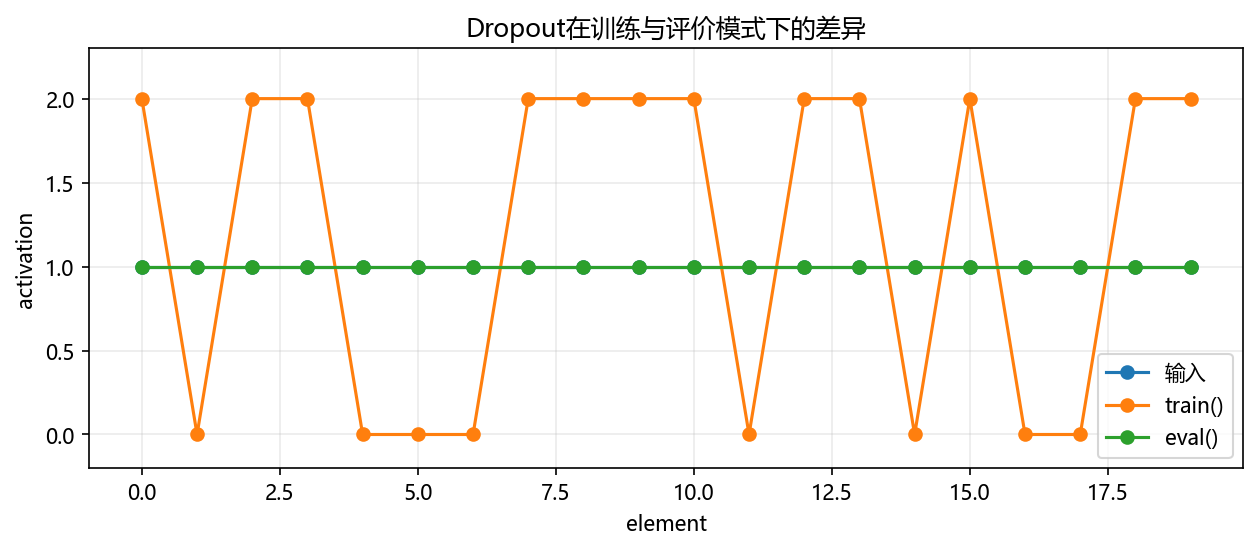

p是**失活概率**，不是保留概率。一次小批量的平均值不一定恰好等于原值，保持的是随机机制下的期望。Dropout不会永久删除层或参数，也不能保证加上后就提高准确率。


### 14.1 no_grad不会关闭Dropout

`eval()` 控制Dropout是否失活；`no_grad()` 控制普通计算是否记录求导图，两者不同。

```python
dropout_layer.train()
with torch.no_grad():
    dropout_still_active = dropout_layer(torch.ones(100))
assert torch.any(dropout_still_active == 0)
assert torch.any(dropout_still_active == 2)
assert not dropout_still_active.requires_grad

dropout_layer.eval()
tracked_input = torch.ones(3, requires_grad=True)
tracked_output = dropout_layer(tracked_input)
tracked_output.sum().backward()
assert torch.equal(tracked_input.grad, torch.ones(3))
```

`F.dropout(x,p=...,training=True)` 是函数形式，training默认True；自定义Module中通常传 `training=self.training`，否则即便外层eval，函数仍可能随机失活。简单顺序网络使用 `nn.Dropout` 更容易跟随模式切换。


## 15. BatchNorm：按特征统计，再学习缩放与平移

对一批数据的某个特征，训练时计算batch均值μB和方差σB²：

$$\hat x=\frac{x-\mu_B}{\sqrt{\sigma_B^2+\epsilon}},
\qquad y=\gamma\hat x+\beta.$$

γ和β通常是可训练参数，初始为1和0。它们不与优化器的betas或EMA的β混为一谈。

`BatchNorm1d(C)` 常用于 `(N,C)` 或 `(N,C,L)`，按通道归一化；`BatchNorm2d(C)` 常用于 `(N,C,H,W)`，按每个通道汇总N、H、W上的统计。不是把每个样本所有特征一起归一化。

```python
bn_input = torch.tensor([[1.0, 10.0], [3.0, 14.0],
                         [5.0, 18.0], [7.0, 22.0]])
bn_layer = nn.BatchNorm1d(2, eps=1e-5, momentum=0.1)
bn_layer.train()
bn_train_output = bn_layer(bn_input)
bn_batch_mean = bn_input.mean(dim=0)
bn_batch_variance = bn_input.var(dim=0, correction=0)
bn_manual_train = (bn_input - bn_batch_mean) / torch.sqrt(bn_batch_variance + 1e-5)
assert torch.allclose(bn_train_output, bn_manual_train, atol=1e-6)
assert torch.allclose(bn_train_output.mean(dim=0), torch.zeros(2), atol=1e-6)
assert torch.equal(bn_layer.weight.detach(), torch.ones(2))
assert torch.equal(bn_layer.bias.detach(), torch.zeros(2))
```

输出并非永远严格均值0、方差1：ε会改变方差，学习后的γ/β也会缩放和平移。BN用于改善训练行为，同时batch统计会产生一定随机性，但不应把所有效果都简单归因于“防止过拟合”或只用某一种理论解释。


## 16. 运行统计量：训练与评价走不同路径

默认 `track_running_stats=True`，训练时维护 `running_mean` 和 `running_var`，评价时使用它们。它们是buffer，随state_dict保存，但不是由优化器学习的Parameter。

PyTorch的BN momentum更新规则为：

$$running_{new}=(1-m)running_{old}+m\cdot batch\_stat.$$

m=0.1表示新batch占10%，与SGD momentum的定义不同。训练前向的方差使用总体形式，更新running_var时使用无偏样本方差。

```python
expected_running_mean = 0.9 * torch.zeros(2) + 0.1 * bn_batch_mean
expected_running_var = 0.9 * torch.ones(2) + 0.1 * bn_input.var(dim=0, correction=1)
assert torch.allclose(bn_layer.running_mean, expected_running_mean)
assert torch.allclose(bn_layer.running_var, expected_running_var)
assert set(dict(bn_layer.named_parameters())) == {"weight", "bias"}
assert "running_mean" in dict(bn_layer.named_buffers())

bn_layer.eval()
with torch.no_grad():
    bn_eval_output = bn_layer(bn_input)
bn_manual_eval = (
    (bn_input - bn_layer.running_mean)
    / torch.sqrt(bn_layer.running_var + bn_layer.eps)
    * bn_layer.weight + bn_layer.bias
)
assert torch.allclose(bn_eval_output, bn_manual_eval, atol=1e-6)
assert not torch.allclose(bn_eval_output, bn_train_output)
```

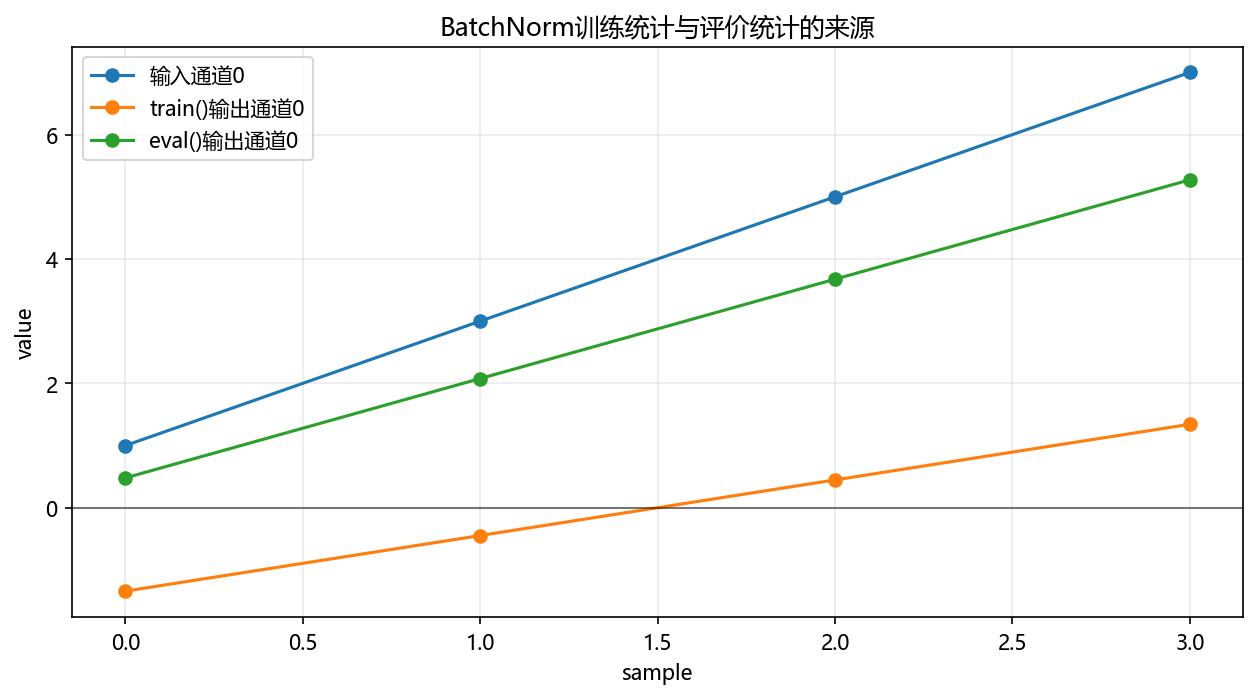

只训练一个batch后，运行统计未充分稳定，eval输出与train输出不同是正常现象。默认BN在eval时不会继续更新这些统计；若 `track_running_stats=False`，train与eval都会用当前batch统计，需要另行理解。


### 16.1 小batch、模式切换与层顺序

对普通 `(N,C)` 输入，训练模式下每个通道只有1个值时，BN无法按常规接口计算所需统计，通常报错；不是所有“batch_size=1”都会报错，例如有空间维度时每通道仍可能有多个值。

常见全连接隐藏块可采用 `Linear → BatchNorm → ReLU → Dropout`。若Linear后紧接带affine的BN，Linear偏置可省略；最终类别logits通常不再加Dropout或BN，但要结合模型设计判断。

```python
regularized_block = nn.Sequential(
    nn.Linear(4, 8, bias=False),
    nn.BatchNorm1d(8),
    nn.ReLU(),
    nn.Dropout(p=0.2),
)
block_input = torch.randn(6, 4)
regularized_block.train()
block_train_output = regularized_block(block_input)
assert block_train_output.shape == (6, 8)
regularized_block.eval()
with torch.no_grad():
    block_eval_first = regularized_block(block_input)
    block_eval_second = regularized_block(block_input)
assert torch.equal(block_eval_first, block_eval_second)
```

训练最后一批若恰好只有1个样本，需要合理安排batch，例如仅对训练loader考虑drop_last=True并说明丢弃的样本。验证和测试通常保留全部样本，eval下默认BN可以处理单样本。BN也不代替输入数据的标准化。


## 17. PyCharm扩展：插件与主题

视频06—07是IDE工具补充。由于未转录视频，本文不把具体插件名单冒充课程原名单。可按下面的需求选择：

| 需求 | 可以查看的位置或功能 |
| --- | --- |
| 阅读Python错误、补全和重构 | 优先熟悉IDE自带的检查与重构功能 |
| Markdown、CSV或其他格式辅助 | Settings/Preferences → Plugins，按实际格式搜索 |
| 调整主题 | Settings/Preferences → Appearance & Behavior → Appearance |
| 编辑器字体与配色 | Editor → Font / Color Scheme |

不同PyCharm版本与系统的菜单名称可能略有变化。安装插件前确认发布者、兼容版本和所需权限，按需要选择即可。主题影响阅读体验，不改变Python运行结果；不要因为装了主题或插件就认为环境依赖已经安装完毕。

本篇只整理操作位置，不实际更改电脑主题或安装IDE插件。


## 18. 手机价格分类：先把需求翻译成数据问题

视频19的需求可以抽象为一个多分类任务：输入手机的若干结构化特征，输出价格档位。价格档位是离散标签，最后一层输出类别logits，训练时使用交叉熵；本篇只完成数据准备，网络与训练放到06。

在拿到真实CSV后，先确认：每行是否代表一部手机、标签列的取值有哪些、特征单位是否一致、缺失值和重复行如何处理。原课程手机数据文件未取得，下面的表格仅为可运行的人工演示，字段和样本量不代表课程原始数据。

```python
phone_demo = pd.DataFrame([
    {"ram_gb": 4,  "storage_gb": 64,  "screen_in": 6.1, "battery_mah": 3200, "camera_mp": 12, "price_level": "low"},
    {"ram_gb": 6,  "storage_gb": 128, "screen_in": 6.4, "battery_mah": 4000, "camera_mp": 48, "price_level": "mid"},
    {"ram_gb": 8,  "storage_gb": 256, "screen_in": 6.7, "battery_mah": 5000, "camera_mp": 64, "price_level": "high"},
    {"ram_gb": 3,  "storage_gb": 64,  "screen_in": 5.9, "battery_mah": np.nan, "camera_mp": 8,  "price_level": "low"},
    {"ram_gb": 12, "storage_gb": 256, "screen_in": 6.8, "battery_mah": 4800, "camera_mp": 108, "price_level": "high"},
    {"ram_gb": 6,  "storage_gb": 128, "screen_in": 6.5, "battery_mah": 4300, "camera_mp": 50, "price_level": "mid"},
    {"ram_gb": 4,  "storage_gb": 128, "screen_in": 6.2, "battery_mah": 3500, "camera_mp": 16, "price_level": "low"},
    {"ram_gb": 8,  "storage_gb": 256, "screen_in": 6.6, "battery_mah": 4500, "camera_mp": 64, "price_level": "high"},
    {"ram_gb": 6,  "storage_gb": 128, "screen_in": 6.3, "battery_mah": 4100, "camera_mp": 48, "price_level": "mid"},
    {"ram_gb": 3,  "storage_gb": 32,  "screen_in": 5.8, "battery_mah": 3000, "camera_mp": 8, "price_level": "low"},
    {"ram_gb": 8,  "storage_gb": 128, "screen_in": 6.5, "battery_mah": 4600, "camera_mp": 50, "price_level": "mid"},
    {"ram_gb": 12, "storage_gb": 512, "screen_in": 6.8, "battery_mah": 5000, "camera_mp": 200, "price_level": "high"},
])
assert phone_demo.isna().sum()["battery_mah"] == 1
phone_demo
```


## 19. 手机表格的数据准备流水线

一个可复用的顺序是：确定特征与标签 → 分层切分 → 用训练集统计量填充缺失特征 → 只用训练集拟合标准化器 → 按固定映射编码标签 → 转成Tensor → DataLoader。切分前就用全量数据计算填充值、均值或标准差，会把测试集信息泄漏到训练过程。

```python
feature_columns = ["ram_gb", "storage_gb", "screen_in", "battery_mah", "camera_mp"]
label_column = "price_level"

prepared = phone_demo.copy()
# 数值缺失值只用训练统计量填充，因此先切分原始行
train_df, test_df = train_test_split(
    prepared, test_size=0.25, random_state=42,
    stratify=prepared[label_column],
)

# 训练集的中位数是预处理参数，测试集只能复用它
fill_values = train_df[feature_columns].median()
train_x_frame = train_df[feature_columns].fillna(fill_values)
test_x_frame = test_df[feature_columns].fillna(fill_values)

scaler = StandardScaler()
train_x = scaler.fit_transform(train_x_frame).astype("float32")
test_x = scaler.transform(test_x_frame).astype("float32")

# 本演示的任务定义预先给出三个类别；编码的编号本身不表示距离
classes = ["low", "mid", "high"]
class_to_index = {name: index for index, name in enumerate(classes)}
assert prepared[label_column].isin(classes).all()
train_y = train_df[label_column].map(class_to_index).to_numpy(dtype="int64")
test_y = test_df[label_column].map(class_to_index).to_numpy(dtype="int64")

x_train_tensor = torch.from_numpy(train_x)
y_train_tensor = torch.from_numpy(train_y)
x_test_tensor = torch.from_numpy(test_x)
y_test_tensor = torch.from_numpy(test_y)
train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
test_dataset = TensorDataset(x_test_tensor, y_test_tensor)
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False)

assert x_train_tensor.dtype == torch.float32
assert y_train_tensor.dtype == torch.int64
assert x_train_tensor.shape[1] == len(feature_columns)
assert set(torch.unique(y_train_tensor).tolist()) <= set(range(len(classes)))
assert len(train_dataset) + len(test_dataset) == len(prepared)
assert set(train_df.index).isdisjoint(test_df.index)
assert not train_x_frame.isna().any().any()
assert not test_x_frame.isna().any().any()
assert np.allclose(scaler.mean_, train_x_frame.mean().to_numpy())
assert np.allclose(train_x.mean(axis=0), 0, atol=1e-6)
assert torch.isfinite(x_train_tensor).all() and torch.isfinite(x_test_tensor).all()
assert set(train_y) == set(test_y) == set(range(len(classes)))
print({"classes": classes, "train": len(train_dataset), "test": len(test_dataset)})
print("first batch:", next(iter(train_loader))[0].shape)
```

运行后得到9条训练样本、3条测试样本，训练batch的shape为 `(4, 5)`。这个12行人工表只用于检查流程，不能用于评价真实手机价格分类能力。

这里使用分层切分，保证小样本演示中各类别出现在两侧；真实数据若某类样本太少，需调整切分方式或先补充数据。分类标签编码必须固定映射，不能让训练集和测试集分别独立编码。之后如果需要调参，应再从训练数据划出验证集；测试集保留给最终评价。


## 20. 数据准备的检查清单

- **特征列**：确认没有把价格标签、ID或未来信息误放进输入。
- **缺失值**：记录填充规则，训练和测试使用同一组训练统计量。
- **尺度**：大数值字段会影响优化，标准化器只在训练集 `fit`。
- **标签**：交叉熵的类别标签通常是从0开始的整数，dtype为`torch.int64`。
- **形状**：特征张量是`(样本数, 特征数)`，标签是一维`(样本数,)`。
- **加载器**：训练集可打乱，验证/测试集通常不打乱；小数据注意`drop_last`是否丢样本。
- **复现**：记录随机种子、切分方式、类别映射和预处理参数。

数据准备完成后，06篇再把`train_loader`接入ANN。若实际数据包含文本、品牌等类别特征，不能直接当作连续数字；应设计编码方式并在训练/验证划分内拟合。


## 21. 常见问题与排查

### Q1：换了Adam，loss还是不降？

检查输入尺度、标签范围、logits与损失函数是否匹配、学习率是否过大，以及是否忘记`zero_grad()`。优化器只能改变更新规则，不能修复错误标签或数据泄漏。

### Q2：scheduler为什么比预期衰减快？

查`scheduler.step()`到底在epoch末还是每个batch调用，并打印每次调用前后的`param_groups[0]["lr"]`。`step_size`和`milestones`的单位就是调用次数。

### Q3：Dropout关闭了吗？

评价前调用整个模型的`eval()`，并用`torch.no_grad()`减少推理开销。只写`no_grad()`不会关闭Dropout；训练恢复时调用`train()`。

### Q4：BatchNorm的输出为什么在train和eval不同？

训练使用当前batch统计，评价使用running统计；训练样本太少时running统计还不稳定。检查模式切换、batch大小和是否误把测试数据用于更新统计。

### Q5：恢复checkpoint后曲线接不上？

除了模型权重，还要恢复优化器和scheduler状态；需要严格复现时同时保存随机数状态、当前epoch和数据采样进度。


## 22. 本篇练习

1. 把第8节二次目标中的起点改成`[-2, 1]`，观察不同优化器是否仍沿相同路径。
2. 将StepLR改成每4轮衰减，写出前12轮实际使用的学习率并用断言验证。
3. 让Dropout的`p`取0.2和0.8，比较10000个元素的非零比例与平均值。
4. 给手机表格增加一行缺失标签，说明为什么不能用普通中位数填充标签。
5. 在同一个ANN中分别比较`train()`和`eval()`下BatchNorm、Dropout的行为，记录一批固定输入的输出差异。

参考答案方向：先打印状态和shape，再写断言；不要只看一次随机输出就下结论。


## 23. 速查

| 任务 | 关键写法 |
| --- | --- |
| 清梯度、反传、更新 | `optimizer.zero_grad()` → `loss.backward()` → `optimizer.step()` |
| 查看当前学习率 | `optimizer.param_groups[0]["lr"]` |
| epoch级衰减 | 训练循环末尾调用 `scheduler.step()` |
| 保存继续训练 | `model`、`optimizer`、`scheduler` 的 `state_dict` |
| Dropout评价 | `model.eval()` + `torch.no_grad()` |
| BN训练统计 | 当前batch均值/方差；更新running统计 |
| 标准化避免泄漏 | `scaler.fit(train)`，再分别 `transform(train/test)` |
| 分类标签 | 从0开始的整数，通常`torch.int64` |

优化器负责“按梯度怎么走”，学习率策略负责“整体步幅怎么变”，Dropout和BatchNorm负责训练过程中的随机失活与统计归一化。它们都需要和数据、模型模式、评估流程一起检查。


## 24. day05目录与来源范围

本篇按网盘目录中已核对的20个day05视频标题组织：梯度回顾、指数移动加权平均、Momentum、AdaGrad、RMSProp、PyCharm插件、PyCharm主题、Adam、优化方法总结、学习率背景、等间隔学习率衰减、指定间隔学习率衰减、指数间隔学习率衰减、学习率总结、Dropout介绍、Dropout代码、BatchNorm介绍、BatchNorm代码、ANN手机价格分类需求、ANN手机价格分类数据准备。

`课堂笔记.zip`、`课件.zip`和手机原始数据正文未取得，视频未逐段转录；本篇的文字、代码、5张图和人工手机表格均为独立编写。图像直接嵌入本Notebook附件，不依赖外部图片文件。第06篇再实现完整ANN手机价格分类训练。
